In [1]:
import os
import numpy as np
import scipy.linalg as sl
from math import factorial

from driven_cavity import (construct_basis_m0, vac, H_drive, evol_list, ng_avg, B_avg, l_distr,
                           build_ops, exp_vals, glueball_dist_analyt)
from bound_states import bound_state_sweep
from glueball_chain import construct_basis_chain_glueball, Heff_glueball, psi_multiglueball, G2_r
from plotting import *

## Figure 3 — glueball condensate under a weak drive

Panel (a) compares the analytic glueball distribution with a coherent state of the same mean. Panels (b, c) compare three descriptions of the same dynamics: **exact** (full driven Hamiltonian), **effective** (H_eff in the glueball ladder) and **analytic** (closed forms). Functions in `driven_cavity.py`.

In [2]:
epsilon, alpha = 0.2, 1.0
Delta = epsilon**2/(3*alpha)
Nmax, lmax = 200, 3

# dimensionless time eps^2 t/U, and the same grid in bare time
lt_eff = np.linspace(0, 5, 200)
lt_exact = lt_eff * alpha / epsilon**2

# diagonalise once, then evolve the vacuum at every time
E, psi_eig = np.linalg.eigh(H_drive(epsilon, Delta, alpha, Nmax, lmax))
psi_t = evol_list(lt_exact, E, psi_eig, vac(Nmax, lmax))

In [3]:
# (a) analytic distribution, against a coherent state of the same mean
t, ng_max = 4, 25
psi2_glueball = np.abs(glueball_dist_analyt(t, ng_max))**2
ng_mean = 3/2*np.sinh(t/3)**2
psi2_coherent = np.zeros(ng_max)
for ng in range(ng_max):
    psi2_coherent[ng] = np.exp(-ng_mean) * ng_mean**(ng)/factorial(ng)

# (b, c) exact: the full driven Hamiltonian
ng_avg_exact = np.array([ng_avg(state, Nmax, lmax) for state in psi_t])
B_avg_exact = np.array([B_avg(state, Nmax, lmax) for state in psi_t])

# (b, c) effective: H_eff exponentiated in the glueball ladder
ng_op, B, Bd = build_ops(Nmax//2+1)
ng_eff_num, B_eff_num = [], []
for t in lt_eff:
    ng_val, Bval = exp_vals(t, ng_op, B, Bd)
    ng_eff_num.append(ng_val)
    B_eff_num.append(Bval)

# (b, c) analytic: closed forms
ng_eff_analytic = 3/2 * np.sinh(lt_eff/3)**2
B_eff_analytic = (np.sqrt(6)/4) * np.sinh(2*lt_eff/3)

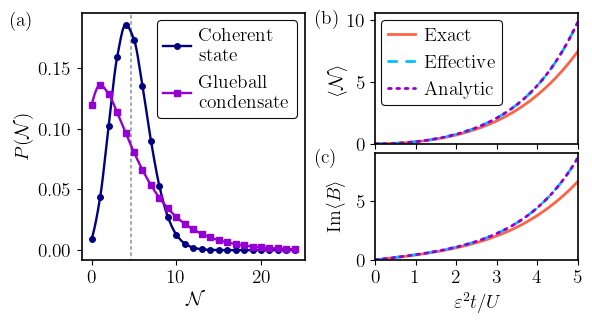

In [4]:
# Figure 3
fig, axes, styles = setup_fig3_format()
ax_a, ax_b, ax_c = axes

# (a) glueball number distribution: smooth line through the points, points on top
for y, s in [(psi2_coherent, styles['coherent']), (psi2_glueball, styles['glueball'])]:
    ax_a.plot(*smooth(y), **s['line'])
    ax_a.plot(y, **s['markers'])
ax_a.vlines(ng_mean, ymin=-0.1, ymax=0.2, **styles['mean'])

# (b, c) exact / effective / analytic dynamics
ng_ys = [ng_avg_exact, ng_eff_num, ng_eff_analytic]
B_ys = [np.imag(B_avg_exact), np.imag(B_eff_num), B_eff_analytic]
for ng_y, B_y, s in zip(ng_ys, B_ys, styles['methods']):
    ax_b.plot(lt_eff, ng_y, **s)
    ax_c.plot(lt_eff, B_y, **s)

finalize_fig3_format(fig, axes, styles)
plt.show()

## Figure 4 — Rabi oscillations and collapse/revival

Same drive as Fig. 3 but at a detuning $\Delta=2U$, which brings the $l=1$ manifold into resonance. Panel (a) starts from the vacuum, panel (b) from the glueball condensate. Both panels are in units of the vacuum Rabi frequency $\Omega_0 = 2\varepsilon$.

In [5]:
# (a) Rabi oscillations from the vacuum
epsilon, alpha = 0.05, 1.0
Delta = -2*alpha # for Rabi
Nmax, lmax = 10, 3
basis, ibasis = construct_basis_m0(Nmax, lmax)
E, psi_eig = np.linalg.eigh(H_drive(epsilon, Delta, alpha, Nmax, lmax))
lt = np.linspace(0, np.pi/epsilon, 100)
psi_t = evol_list(lt, E, psi_eig, vac(Nmax, lmax))

lt_scaled_a = lt * 2 * epsilon   # rescale to Omega_0 * t
populations = {(N, l): np.abs(psi_t[:, ibasis[N,l]])**2 for N, l in [(0,0), (1,1), (2,0), (2,2)]}

In [6]:
# (b) 1. prepare the glueball condensate
epsilon, alpha = 0.05, 1.0     # weak drive regime
Delta = epsilon**2/(3*alpha)   # use the same regime as Heff derivation
Nmax, lmax = 160, 3
t_prep = 3*alpha/epsilon**2    # t_eff = 3 (xi = 1)
psi0 = sl.expm(-1j * H_drive(epsilon, Delta, alpha, Nmax, lmax) * t_prep) @ vac(Nmax, lmax)

# (b) 2. excite it, and follow <L^2>
Delta = -2*alpha
E, psi_eig = np.linalg.eigh(H_drive(epsilon, Delta, alpha, Nmax, lmax))
lt = np.linspace(0, 5*np.pi/epsilon, 300)
psi_t = evol_list(lt, E, psi_eig, psi0)

lt_scaled_b = lt * 2 * epsilon   # rescale to Omega_0 * t
l_list = np.arange(lmax+1)
J2_avg = np.array([np.sum(l_list*(l_list+1)*l_distr(psi, Nmax, lmax)) for psi in psi_t])

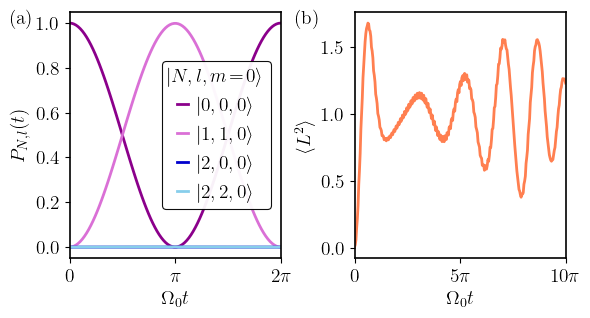

In [7]:
# Figure 4
fig, axes, styles = setup_fig4_format()
ax_a, ax_b = axes

# (a) Rabi oscillations between |0,0,0> and |1,1,0>
for ((N, l), P), s in zip(populations.items(), styles['populations']):
    ax_a.plot(lt_scaled_a, P, label=rf'$|{N},{l},0\rangle$', **s)

# (b) collapse and revival of <L^2>, starting from the glueball condensate
ax_b.plot(lt_scaled_b, J2_avg, **styles['L2'])

finalize_fig4_format(fig, axes)
plt.show()

## Figure 5(b, c) — two-glueball bound state

Relative-coordinate problem, Eq. (48); functions in `bound_states.py`. Panels (b) and (c) are exported separately and combined with the array sketch (a) afterwards.

Panel (b): sweep the centre-of-mass momentum $K$ across the full zone.

In [8]:
ps = np.linspace(0, 2*np.pi, 50, endpoint=True)
E, V_bound, bound_state_E = bound_state_sweep(ps, ncav=300)

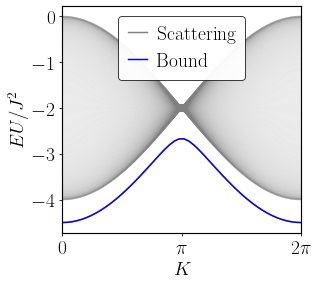

In [9]:
# Figure 5(b) -- two-glueball spectrum over the full Brillouin zone
fig, ax_b, styles = setup_fig5b_format()

ax_b.plot(ps, E, **styles['spectrum'])
ax_b.plot(ps, bound_state_E, **styles['scattering'])
ax_b.plot(ps, bound_state_E, **styles['bound'])

finalize_fig5b_format(fig, ax_b)
plt.show()

Panel (c): the same over half the zone, keeping the bound state at each $K$. 

In [10]:
ps = np.linspace(0, np.pi, 300, endpoint=True)
E, V_bound, bound_state_E = bound_state_sweep(ps, ncav=300)

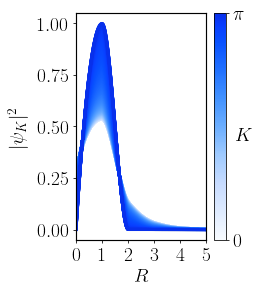

In [11]:
# Figure 5(c) -- bound-state wavefunction, half the zone; smooth line through R = 0..5
fig, ax_c, styles = setup_fig5c_format(ps)

for v, s in zip(V_bound, styles['lines']):
    P_low = np.abs(v)**2
    ax_c.plot(*smooth(P_low[:6]), **s)

finalize_fig5c_format(fig, ax_c, ps, styles)
plt.show()

## Figure 6 — many-glueball bound states

Full Fock-space diagonalisation of the effective glueball chain, $\mathcal{N} = 2,\dots,5$ glueballs on $M = 14$ periodic sites. At $\mathcal{N} = 2$ it lands on the same ratio $P([0,0])/P([0,1]) = 8/15$ as the relative-coordinate problem of Fig. 5(c). Functions in `glueball_chain.py`.

Ground state of the chain for each glueball number, stored in `data/`. Computing them is a dense diagonalisation, about 6 min for $\mathcal{N} = 5$ (dimension 8568), so by default this cell only fills in missing files; set `regenerate = True` to recompute all of them.

In [12]:
regenerate = False   # True: recompute the ground states (~6 min) instead of using the ones in data/

ngs, ncav, t, periodic = [2, 3, 4, 5], 14, 1, True
os.makedirs("data", exist_ok=True)
for ng in ngs:
    path = f"data/fig6_ground_state_ng{ng}.npz"
    if regenerate or not os.path.exists(path):
        evalues, estates = np.linalg.eigh(Heff_glueball(ng, ncav, t=t, periodic=periodic))
        np.savez_compressed(path, psi0=estates[:,0], E0=evalues[0], ng=ng, ncav=ncav, t=t, periodic=periodic)

Probabilities of a few fixed configurations (glueball positions, first glueball at site 0), relative to the most likely one; and the correlator $G_2(r)$.

In [13]:
ngs = [2, 3, 4, 5]
positions2 = [[0,0], [0,1], [0,2],[0,7]]
positions3 = [[0,0,0], [0,0,1], [0,1,2], [0,1,3], [0,1,4], [0,2,4], [0,0,4], [0,0,7]]
positions4 = [[0,0,0,0], [0,0,0,1], [0,0,1,1], [0,0,1,2], [0,1,1,2], [0,1,2,3], [0,0,0,4], [0,0,0,7]]
positions5 = [[0,0,0,1,1], [0,1,1,1,2], [0,0,0,0,0], [0,0,1,1,2], [0,0,1,2,2], [0,1,2,3,4], [0,1,1,1,1], [0,1,6,7,7]]
positions_all = [positions2, positions3, positions4, positions5]

probs_all, positions_all_sorted, corr_all = [], [], []
for ng, positions in zip(ngs, positions_all):
    ground_state = np.load(f"data/fig6_ground_state_ng{ng}.npz")
    psi0, ncav = ground_state['psi0'], int(ground_state['ncav'])
    basis, ibasis = construct_basis_chain_glueball(ng, ncav)

    # (main) configuration probabilities, largest first
    psi2 = np.abs(psi_multiglueball(ng, psi0, basis, ibasis))**2
    probs = np.array([psi2[*pos] for pos in positions])
    probs = probs/np.max(probs)
    sort_idx = list(reversed(probs.argsort()))
    probs_all.append(probs[sort_idx])
    positions_all_sorted.append(np.array(positions)[sort_idx])

    # (inset) density-density correlator
    corr_all.append(G2_r(psi0, basis)/(ng*(ng-1)))

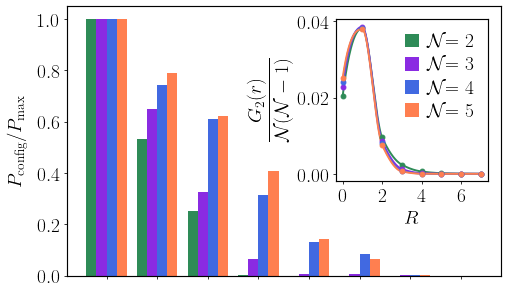

In [16]:
# Figure 6
fig, axes, styles = setup_fig6_format()
ax, axins = axes

# (main) configuration probabilities, one group of bars per configuration rank
for probs, dx, s in zip(probs_all, styles['bar_offsets'], styles['bars']):
    ax.bar(np.arange(len(probs)) + dx, probs, **s)

# (inset) G2(R) for R = 0..7 = M/2: smooth line through the points, points on top
crop = 8
for corr, line, markers in zip(corr_all, styles['G2_lines'], styles['G2_markers']):
    axins.plot(*smooth(corr[:crop]), **line)
    axins.plot(corr[:crop], **markers)

finalize_fig6_format(fig, axes, styles, ngs, nconfigs=len(probs_all[-1]))
plt.savefig('manybody_inset.pdf', bbox_inches='tight')
plt.show()